# Clasificador de Spam: Naive Bayes vs kNN vs SVM

Clasificación supervisada de mensajes SMS en **ham** (legítimos) y **spam** usando TF-IDF y tres algoritmos clásicos.

Las funciones de limpieza y los modelos se importan de `clasificador_spam.py`, de modo que el notebook y el script siempre producen los mismos resultados.

## 1. Importación de Librerías

In [1]:
import time

import joblib
import matplotlib.pyplot as plt
import pandas as pd
import seaborn as sns
from sklearn.metrics import (accuracy_score, classification_report,
                             confusion_matrix, f1_score)
from sklearn.model_selection import (StratifiedKFold, cross_validate,
                                     train_test_split)

from clasificador_spam import (SEMILLA, STOP_WORDS, cargar_datos,
                               crear_modelos, limpiar_texto)

## 2. Carga de Datos

El dataset tiene dos columnas:
- `label`: "spam" o "ham"
- `text`: contenido del mensaje

In [2]:
df = cargar_datos("dataset_spam.csv")
total_original = len(df)
print(f"Total de mensajes: {total_original}")
df.head()

Total de mensajes: 5572


,label,text
0,ham,"Go until jurong point, crazy.. Available only ..."
1,ham,Ok lar... Joking wif u oni...
2,spam,Free entry in 2 a wkly comp to win FA Cup fina...
3,ham,U dun say so early hor... U c already then say...
4,ham,"Nah I don't think he goes to usf, he lives aro..."


In [3]:
print("Distribución de clases:")
print(df['label'].value_counts())
print("\nPorcentajes:")
print((df['label'].value_counts(normalize=True) * 100).round(2))

Distribución de clases:
label
ham     4825
spam     747
Name: count, dtype: int64

Porcentajes:
label
ham     86.59
spam    13.41
Name: proportion, dtype: float64


## 3. Limpieza del Texto (Paso Cero)

`limpiar_texto` aplica:
1. Conversión a minúsculas
2. Eliminación de URLs
3. Eliminación de números
4. Eliminación de puntuación
5. Tokenización
6. Eliminación de stop words (NLTK, inglés)
7. **Stemming** de Porter (con caché, porque las mismas palabras se repiten miles de veces)

In [4]:
print(f"Stopwords cargadas: {len(STOP_WORDS)}")
texto_ejemplo = df['text'].iloc[3]
print("\nTexto original:")
print(texto_ejemplo)
print("\nTexto limpio:")
print(limpiar_texto(texto_ejemplo))

Stopwords cargadas: 198

Texto original:
U dun say so early hor... U c already then say...

Texto limpio:
u dun say earli hor u c alreadi say


In [5]:
t0 = time.perf_counter()
df['clean'] = df['text'].map(limpiar_texto)
print(f"Limpieza completada en {time.perf_counter() - t0:.2f} s")
df[['text', 'clean', 'label']].head()

Limpieza completada en 0.16 s


,text,clean,label
0,"Go until jurong point, crazy.. Available only ...",go jurong point crazi avail bugi n great world...,ham
1,Ok lar... Joking wif u oni...,ok lar joke wif u oni,ham
2,Free entry in 2 a wkly comp to win FA Cup fina...,free entri wkli comp win fa cup final tkt st m...,spam
3,U dun say so early hor... U c already then say...,u dun say earli hor u c alreadi say,ham
4,"Nah I don't think he goes to usf, he lives aro...",nah dont think goe usf live around though,ham


### 3.1 Mensajes vacíos y duplicados

Algunos mensajes quedan vacíos tras la limpieza. Además, el dataset contiene muchos mensajes **repetidos** (por ejemplo, la misma promoción enviada a varias personas). Si un mensaje repetido cae a la vez en entrenamiento y en prueba, el modelo se evalúa con datos que ya vio y los resultados se inflan. Por eso se eliminan.

In [6]:
n_vacios = (df['clean'].str.strip() == '').sum()
df = df[df['clean'].str.strip() != '']
n_duplicados = df.duplicated(subset='clean').sum()
df = df.drop_duplicates(subset='clean').reset_index(drop=True)

print(f"Vacíos eliminados: {n_vacios}")
print(f"Duplicados eliminados: {n_duplicados}")
print(f"Mensajes usados: {len(df)} de {total_original}")
print("\nDistribución final:")
print(df['label'].value_counts())

Vacíos eliminados: 6
Duplicados eliminados: 501
Mensajes usados: 5065 de 5572

Distribución final:
label
ham     4481
spam     584
Name: count, dtype: int64


## 4. División Train/Test (Paso Uno)

70% entrenamiento y 30% prueba, **estratificado** para que ambos conjuntos tengan la misma proporción de ham y spam.

In [7]:
X, y = df['clean'], df['label']
X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.3, random_state=SEMILLA, stratify=y)

print(f"Entrenamiento: {X_train.shape[0]} mensajes")
print(f"Prueba: {X_test.shape[0]} mensajes")
print("\nProporción de spam:")
print(f"  entrenamiento: {(y_train == 'spam').mean() * 100:.2f}%")
print(f"  prueba:        {(y_test == 'spam').mean() * 100:.2f}%")

Entrenamiento: 3545 mensajes
Prueba: 1520 mensajes

Proporción de spam:
  entrenamiento: 11.54%
  prueba:        11.51%


## 5. Vectorización TF-IDF y Modelos (Paso Dos)

Cada modelo es un `Pipeline` **TF-IDF → clasificador**. Así, el vocabulario y los pesos IDF se aprenden **solo con el conjunto de entrenamiento**; ajustar TF-IDF con todo el dataset filtraría información del conjunto de prueba.

Configuración de TF-IDF:
- `ngram_range=(1, 2)`: palabras y pares de palabras ("free entri", "call now")
- `sublinear_tf=True`: usa 1 + log(tf) para que una palabra repetida no domine
- `min_df=2`: ignora términos que aparecen en un solo mensaje
- `dtype=float32`: la mitad de memoria

Clasificadores:
- **Naive Bayes** multinomial con `alpha=0.1`
- **kNN** con k=5, distancia **coseno** (la adecuada para vectores TF-IDF) y voto ponderado por distancia
- **SVM** lineal (`LinearSVC`, C=1)

In [8]:
modelos = crear_modelos()
predicciones = {}
for nombre, modelo in modelos.items():
    t0 = time.perf_counter()
    modelo.fit(X_train, y_train)
    t_fit = time.perf_counter() - t0
    t0 = time.perf_counter()
    predicciones[nombre] = modelo.predict(X_test)
    t_pred = time.perf_counter() - t0
    print(f"{nombre:12s}: entrenamiento {t_fit:.3f} s | predicción {t_pred:.3f} s")

Naive Bayes : entrenamiento 0.055 s | predicción 0.016 s


kNN         : entrenamiento 0.052 s | predicción 0.082 s


SVM         : entrenamiento 0.057 s | predicción 0.016 s


In [9]:
tfidf = modelos['SVM'].named_steps['tfidf']
vocab = tfidf.get_feature_names_out()
print(f"Tamaño del vocabulario (unigramas + bigramas): {len(vocab)}")
print("Algunos términos:", list(vocab[1000:1020]))

Tamaño del vocabulario (unigramas + bigramas): 4799
Algunos términos: ['dload', 'dload polyph', 'dnt', 'dobbi', 'doc', 'dock', 'doctor', 'doesnt', 'doesnt need', 'dog', 'dog locat', 'dog network', 'doggi', 'doggi style', 'doin', 'dollar', 'don', 'done', 'done hand', 'done im']


## 6. Evaluación de Resultados

In [10]:
for nombre, pred in predicciones.items():
    print("=" * 60)
    print(f"{nombre.upper()} - Reporte de Clasificación")
    print("=" * 60)
    print(classification_report(y_test, pred, digits=4))

NAIVE BAYES - Reporte de Clasificación
              precision    recall  f1-score   support

         ham     0.9845    0.9926    0.9885      1345
        spam     0.9390    0.8800    0.9086       175

    accuracy                         0.9796      1520
   macro avg     0.9618    0.9363    0.9485      1520
weighted avg     0.9793    0.9796    0.9793      1520

KNN - Reporte de Clasificación
              precision    recall  f1-score   support

         ham     0.9710    0.9955    0.9831      1345
        spam     0.9574    0.7714    0.8544       175

    accuracy                         0.9697      1520
   macro avg     0.9642    0.8835    0.9188      1520
weighted avg     0.9694    0.9697    0.9683      1520

SVM - Reporte de Clasificación
              precision    recall  f1-score   support

         ham     0.9845    0.9911    0.9878      1345
        spam     0.9277    0.8800    0.9032       175

    accuracy                         0.9783      1520
   macro avg     0.9561    

## 7. Comparación Final de Modelos

Como el spam es solo ~11.5% de los mensajes, un modelo que dijera "ham" siempre tendría 88.5% de accuracy. Por eso se ordena por **F1 de la clase spam**, que combina precisión y recall de la clase que importa detectar.

In [11]:
resultados = pd.DataFrame({
    nombre: {
        'Accuracy (%)': accuracy_score(y_test, pred) * 100,
        'F1 spam': f1_score(y_test, pred, pos_label='spam'),
    }
    for nombre, pred in predicciones.items()
}).T.sort_values('F1 spam', ascending=False)

mejor_modelo = resultados.index[0]
print(f"Mejor modelo (por F1 de spam): {mejor_modelo}")
resultados.round(4)

Mejor modelo (por F1 de spam): Naive Bayes


,Accuracy (%),F1 spam
Naive Bayes,97.9605,0.9086
SVM,97.8289,0.9032
kNN,96.9737,0.8544


### 7.1 Validación cruzada

Un solo split train/test puede favorecer a un modelo por azar. Con validación cruzada estratificada de 5 particiones se obtiene la media y la desviación estándar de cada métrica.

In [12]:
skf = StratifiedKFold(n_splits=5, shuffle=True, random_state=SEMILLA)
filas = {}
for nombre, modelo in crear_modelos().items():
    cv = cross_validate(modelo, X, y, cv=skf, n_jobs=-1,
                        scoring={'acc': 'accuracy', 'f1': 'f1_macro'})
    filas[nombre] = {
        'Accuracy media (%)': cv['test_acc'].mean() * 100,
        'Accuracy desv. (%)': cv['test_acc'].std() * 100,
        'F1 macro media': cv['test_f1'].mean(),
        'F1 macro desv.': cv['test_f1'].std(),
    }
resultados_cv = pd.DataFrame(filas).T
resultados_cv.round(4)

,Accuracy media (%),Accuracy desv. (%),F1 macro media,F1 macro desv.
Naive Bayes,98.0454,0.4812,0.9494,0.0135
kNN,97.0385,0.5722,0.9187,0.0180
SVM,97.9467,0.4253,0.9467,0.0121


## 8. Visualización de Resultados

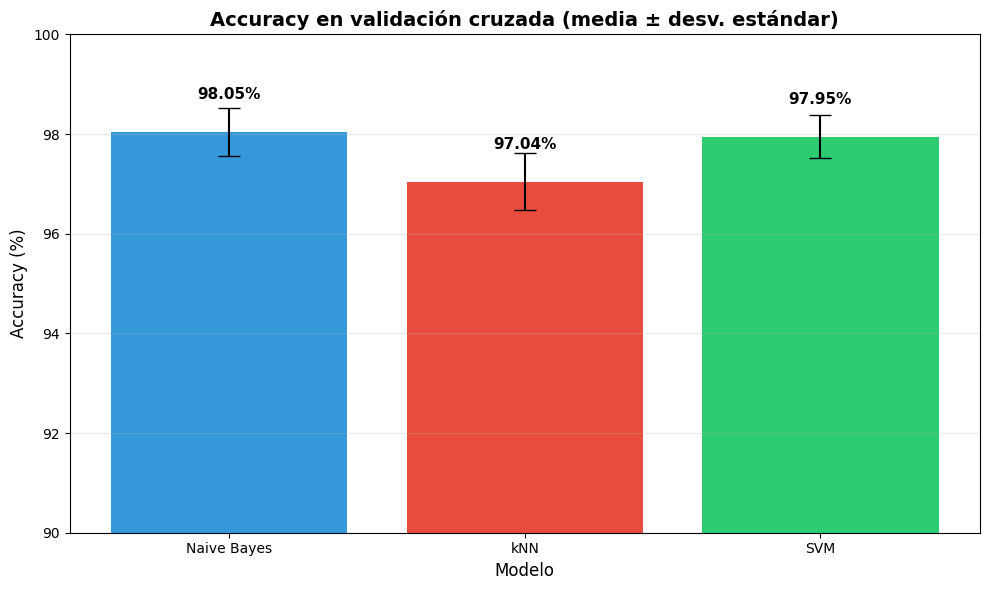

In [13]:
fig, ax = plt.subplots(figsize=(10, 6))
orden = resultados_cv.index
medias = resultados_cv['Accuracy media (%)']
desv = resultados_cv['Accuracy desv. (%)']
barras = ax.bar(orden, medias, yerr=desv, capsize=8,
                color=['#3498db', '#e74c3c', '#2ecc71'])
ax.set_ylabel('Accuracy (%)', fontsize=12)
ax.set_xlabel('Modelo', fontsize=12)
ax.set_title('Accuracy en validación cruzada (media ± desv. estándar)',
             fontsize=14, fontweight='bold')
ax.set_ylim(90, 100)
for barra, m in zip(barras, medias):
    ax.text(barra.get_x() + barra.get_width() / 2, m + 0.6, f'{m:.2f}%',
            ha='center', va='bottom', fontsize=11, fontweight='bold')
ax.grid(axis='y', alpha=0.3)
plt.tight_layout()
plt.show()

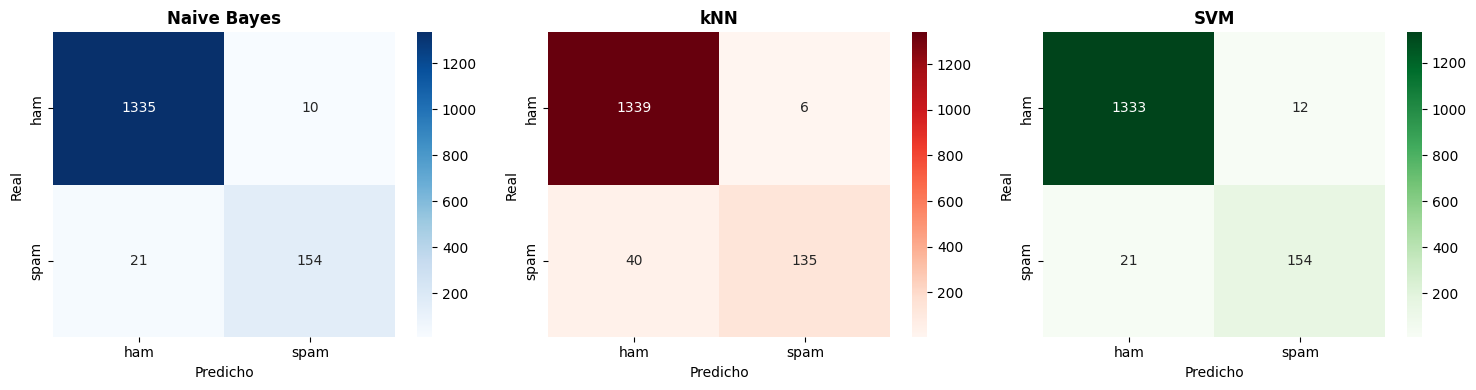

In [14]:
fig, axes = plt.subplots(1, 3, figsize=(15, 4))
colores = {'Naive Bayes': 'Blues', 'kNN': 'Reds', 'SVM': 'Greens'}
for ax, (nombre, pred) in zip(axes, predicciones.items()):
    sns.heatmap(confusion_matrix(y_test, pred, labels=['ham', 'spam']),
                annot=True, fmt='d', cmap=colores[nombre], ax=ax,
                xticklabels=['ham', 'spam'], yticklabels=['ham', 'spam'])
    ax.set_title(nombre, fontweight='bold')
    ax.set_ylabel('Real')
    ax.set_xlabel('Predicho')
plt.tight_layout()
plt.show()

## 9. Prueba del Modelo con Mensajes Nuevos

Como cada modelo es un `Pipeline`, basta con limpiar el texto y llamar a `predict`; la vectorización TF-IDF ocurre dentro.

In [15]:
def clasificar_mensaje(mensaje, modelo=modelos[mejor_modelo]):
    return modelo.predict([limpiar_texto(mensaje)])[0]

mensajes_prueba = [
    "Congratulations! You've won a FREE prize worth $1000. Click here to claim now!",
    "Hey, are we still meeting for lunch tomorrow?",
    "URGENT: Your account will be suspended unless you verify your details immediately",
    "Thanks for the notes from class. See you on Monday!",
    "URGENT HOLAA NECESITAS DINERO YO PUEDO AYUDARTE",
]

print(f"Clasificación de mensajes nuevos usando {mejor_modelo}:\n")
for i, msg in enumerate(mensajes_prueba, 1):
    print(f"Mensaje {i}: {clasificar_mensaje(msg).upper()}")
    print(f"   '{msg}'\n")

Clasificación de mensajes nuevos usando Naive Bayes:

Mensaje 1: SPAM
   'Congratulations! You've won a FREE prize worth $1000. Click here to claim now!'

Mensaje 2: HAM
   'Hey, are we still meeting for lunch tomorrow?'

Mensaje 3: SPAM
   'URGENT: Your account will be suspended unless you verify your details immediately'

Mensaje 4: HAM
   'Thanks for the notes from class. See you on Monday!'

Mensaje 5: SPAM
   'URGENT HOLAA NECESITAS DINERO YO PUEDO AYUDARTE'



## 10. Guardar el Modelo

Se reentrena el mejor modelo con todos los datos y se guarda con `joblib`; después puede cargarse y usarse sin volver a entrenar.

In [16]:
final = crear_modelos()[mejor_modelo].fit(X, y)
joblib.dump(final, 'modelo_spam.joblib')

cargado = joblib.load('modelo_spam.joblib')
print(cargado.predict([limpiar_texto('Free entry! Text WIN to 80086 now')]))

['spam']


## 11. Conclusiones

### Hallazgos principales
1. **Naive Bayes y SVM quedan prácticamente empatados** (~98% de accuracy). La diferencia entre ambos es menor que la variación entre particiones de la validación cruzada, por lo que no puede afirmarse que uno sea superior.
2. **kNN mejoró mucho** respecto a la versión anterior (de 91.27% a ~97%) al usar distancia coseno y voto ponderado, aunque sigue siendo el más débil en recall de spam.
3. **La evaluación anterior estaba inflada**: los mensajes duplicados y el ajuste de TF-IDF con todo el dataset hacían que el modelo se evaluara en parte con datos ya vistos.

### Métricas clave
- **Precision**: evita marcar mensajes legítimos como spam (falsos positivos)
- **Recall**: detecta la mayor cantidad de spam posible
- **F1-Score**: balance entre ambas; con clases desbalanceadas es mejor criterio que el accuracy

### Próximos pasos
- Ajustar hiperparámetros con `GridSearchCV` (C de SVM, alpha de NB, k de kNN, n-gramas)
- `class_weight="balanced"` en SVM para aumentar el recall de spam
- N-gramas de caracteres para capturar variaciones como "fr33" o "w1n"
- Representaciones semánticas (embeddings, modelos tipo BERT)